# 03 · Shot context, player differences, and feature relationships

The question is whether a specific player makes a shot under a given context. [Notebook 01](01_understand_shot_logs.ipynb) established the archive's structure and reviewed unusual shot distances. [Notebook 02](02_tracking_value_anomalies.ipynb) investigated tracking anomalies. This notebook explores the relationships that will inform modeling.

There is no compulsory sports EDA checklist. The common questions for shot-level data are whether the sample represents the intended games and players, how shot difficulty relates to outcomes, which relationships survive comparisons within similar shots, how much evidence each player has, and whether patterns change over time. Averages across all shots can conceal differences in shot selection. Shots from the same player or game also share context.

| Exploration | What it answers here |
| --- | --- |
| Distributions and coverage | Which shots, players, and situations are represented? |
| Conditional rates and sample counts | How does make rate vary with shot context? |
| Correlation matrices and scatterplots | Which numeric features move together, and how? |
| Player and time comparisons | Where might pooled averages or evaluation become misleading? |
| One-hot encoding | How can categories become model inputs without imposing a numeric order? |
| PCA | Can a few directions summarize the variation in numeric shot context? |

Encoding and PCA are preprocessing methods we inspect here. They do not establish which inputs will improve predictions. All exploration uses games before February 1, 2015. Transformers learn their parameters on dates before January 1 and are applied to January as an example of using earlier data to process later data. [Scikit-learn guidance on leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.plotting import scatter_matrix
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
raw = pd.read_csv(root / "data/raw/shot_logs.csv", dtype={"GAME_ID": "string"})
dates = pd.to_datetime(raw["MATCHUP"].str.split(" - ", n=1).str[0], format="%b %d, %Y")
shots = raw.loc[dates.lt("2015-02-01")].copy()
shots["GAME_DATE"] = dates.loc[shots.index]
shots["GAME_ID"] = shots["GAME_ID"].str.zfill(10)
parts = shots["GAME_CLOCK"].str.split(":", expand=True).astype(int)
shots["PERIOD_SECONDS"] = parts[0] * 60 + parts[1]
shot_key = ["GAME_ID", "player_id", "SHOT_NUMBER"]
assert not shots.duplicated(shot_key).any()

# Use the four reviewed 2-ft corrections from Notebook 01.
reviewed_keys = pd.MultiIndex.from_tuples([
    ("0021400589", 201600, 5), ("0021400378", 201163, 6),
    ("0021400671", 201601, 10), ("0021400702", 201596, 5),
])
corrected = pd.MultiIndex.from_frame(shots[shot_key]).isin(reviewed_keys)
assert corrected.sum() == 4 and shots.loc[corrected, "SHOT_DIST"].eq(0).all()
shots["SHOT_DIST_CLEAN"] = shots["SHOT_DIST"].mask(corrected, 2.0)
shots["TOUCH_TIME_CLEAN"] = shots["TOUCH_TIME"].mask(shots["TOUCH_TIME"].lt(0))
shots["SHOT_CLOCK_CLEAN"] = shots["SHOT_CLOCK"]
shots["CLOCK_SOURCE"] = np.where(shots["SHOT_CLOCK"].notna(), "Recorded", "Unresolved")
late_blank = shots["SHOT_CLOCK"].isna() & shots["PERIOD_SECONDS"].le(24)
shots.loc[late_blank, "SHOT_CLOCK_CLEAN"] = shots.loc[late_blank, "PERIOD_SECONDS"]
shots.loc[late_blank, "CLOCK_SOURCE"] = "Period proxy"

# Reuse the cached audit from Notebook 02. A missing audit requires an explicit rerun.
audit_path = root / "data/processed/shot-clock-review/missing-shot-clocks.csv"
if not audit_path.is_file():
    raise FileNotFoundError(
        "Run src/reconstruct_shot_clock.py data/raw/shot_logs.csv first. "
        "See docs/shot-clock-reconstruction.md."
    )
audit = pd.read_csv(audit_path, dtype={"game_id": "string"})
audit["game_id"] = audit["game_id"].str.zfill(10)
estimates = audit.loc[audit["status"].eq("estimated")].set_index(
    ["game_id", "player_id", "shot_number"], verify_integrity=True,
)["estimated_shot_clock"]
reconstructed = pd.Series(
    estimates.reindex(pd.MultiIndex.from_frame(shots[shot_key])).to_numpy(),
    index=shots.index,
)
use_estimate = shots["SHOT_CLOCK"].isna() & reconstructed.between(0, 24)
shots.loc[use_estimate, "SHOT_CLOCK_CLEAN"] = reconstructed.loc[use_estimate]
shots.loc[use_estimate, "CLOCK_SOURCE"] = "Possession estimate"

assert shots.loc[shots["SHOT_CLOCK"].notna(), "SHOT_CLOCK_CLEAN"].equals(
    shots.loc[shots["SHOT_CLOCK"].notna(), "SHOT_CLOCK"]
)
assert shots["TOUCH_TIME_CLEAN"].isna().sum() == 258
assert shots["SHOT_CLOCK_CLEAN"].isna().sum() == 1239
assert shots["GAME_DATE"].max() < pd.Timestamp("2015-02-01")
print(f"{len(shots):,} attempts, {shots['GAME_ID'].nunique():,} games, "
      f"{shots['player_id'].nunique():,} shooters.")
display(shots["CLOCK_SOURCE"].value_counts().to_frame("Attempts"))

101,997 attempts, 710 games, 281 shooters.


,Attempts
CLOCK_SOURCE,
Recorded,97371
Period proxy,2829
Unresolved,1239
Possession estimate,558


Keep exact zero and extreme defender distances as recorded. Negative touch times become missing, and the four reviewed zero basket distances become 2 ft. The clock column contains measured values, estimates, and period-clock proxies. The provenance table above documents that mixture. The late proxy may overstate time available, while the reconstruction audit found 1.44 s mean absolute error on the subset of known clocks it could estimate.

## 1. Define the target and eligible inputs

Make or miss is a binary target. Shot value distinguishes twos and threes. Player identity represents who took the shot, but an ID's numeric magnitude has no basketball meaning. Defender identity can help describe coverage, although it also reflects matchups and player roles.

The forecast is conditional on the shot context at release. Postgame information would give the model information unavailable at that moment. There are no court coordinates in this CSV, so this notebook can compare distance bands but cannot locate corner threes or distinguish left from right.

In [2]:
roles = pd.DataFrame([
    ("Target", "FGM", "1 = made, 0 = missed"),
    ("Outcome duplicates", "SHOT_RESULT, PTS", "Exclude from inputs"),
    ("Postgame results", "W, FINAL_MARGIN", "Exclude from inputs"),
    ("Continuous context", "SHOT_DIST_CLEAN, CLOSE_DEF_DIST, TOUCH_TIME_CLEAN, SHOT_CLOCK_CLEAN", "At-shot measurements or documented estimates"),
    ("Other context", "DRIBBLES, PERIOD, PERIOD_SECONDS, PTS_TYPE, LOCATION", "Counts, time, shot value, home/away"),
    ("Categories", "player_id, CLOSEST_DEFENDER_PLAYER_ID", "Represent identity as a category"),
    ("Keys and chronology", "GAME_ID, MATCHUP, GAME_DATE, SHOT_NUMBER", "Grouping, matching, chronological ordering"),
], columns=["Role", "Fields", "Use"])
display(roles)
target = shots.groupby("PTS_TYPE").agg(
    attempts=("FGM", "size"), make_pct=("FGM", lambda x: 100 * x.mean()),
    points_per_attempt=("PTS", "mean"),
)
display(target.round(3))
print(f"Overall make rate: {shots['FGM'].mean():.1%}")
print(f"Majority-class share: {shots['FGM'].value_counts(normalize=True).max():.1%}")

,Role,Fields,Use
0,Target,FGM,"1 = made, 0 = missed"
1,Outcome duplicates,"SHOT_RESULT, PTS",Exclude from inputs
2,Postgame results,"W, FINAL_MARGIN",Exclude from inputs
3,Continuous context,"SHOT_DIST_CLEAN, CLOSE_DEF_DIST, TOUCH_TIME_CL...",At-shot measurements or documented estimates
4,Other context,"DRIBBLES, PERIOD, PERIOD_SECONDS, PTS_TYPE, LO...","Counts, time, shot value, home/away"
5,Categories,"player_id, CLOSEST_DEFENDER_PLAYER_ID",Represent identity as a category
6,Keys and chronology,"GAME_ID, MATCHUP, GAME_DATE, SHOT_NUMBER","Grouping, matching, chronological ordering"


,attempts,make_pct,points_per_attempt
PTS_TYPE,,,
2,75050,48.983,0.980
3,26947,35.381,1.061


Overall make rate: 45.4%
Majority-class share: 54.6%


Points per attempt counts only points credited to these recorded field-goal attempts. It excludes free throws and other possession outcomes. The majority-class share describes imbalance and will not be enough to evaluate probability quality later.

## 2. Feature distributions and coverage

Inspect full ranges before interpreting typical values. The histograms show every retained value. Differences between the median, upper quantiles, and maximum reveal skew and sparse extremes.

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,missing
SHOT_DIST_CLEAN,101997.0,13.56,8.89,0.1,0.7,4.7,13.6,22.5,25.5,27.7,47.2,0
CLOSE_DEF_DIST,101997.0,4.12,2.75,0.0,0.1,2.3,3.7,5.3,8.8,14.1,53.2,0
TOUCH_TIME_CLEAN,101739.0,2.78,2.98,0.0,0.0,0.9,1.6,3.7,8.8,14.8,24.9,258
DRIBBLES,101997.0,2.02,3.48,0.0,0.0,0.0,1.0,2.0,9.0,17.0,32.0,0
SHOT_CLOCK_CLEAN,100758.0,12.21,5.90,0.0,0.8,7.9,12.1,16.5,22.4,24.0,24.0,1239
PERIOD_SECONDS,101997.0,351.24,207.82,0.0,1.0,172.0,352.0,531.0,675.0,705.0,720.0,0


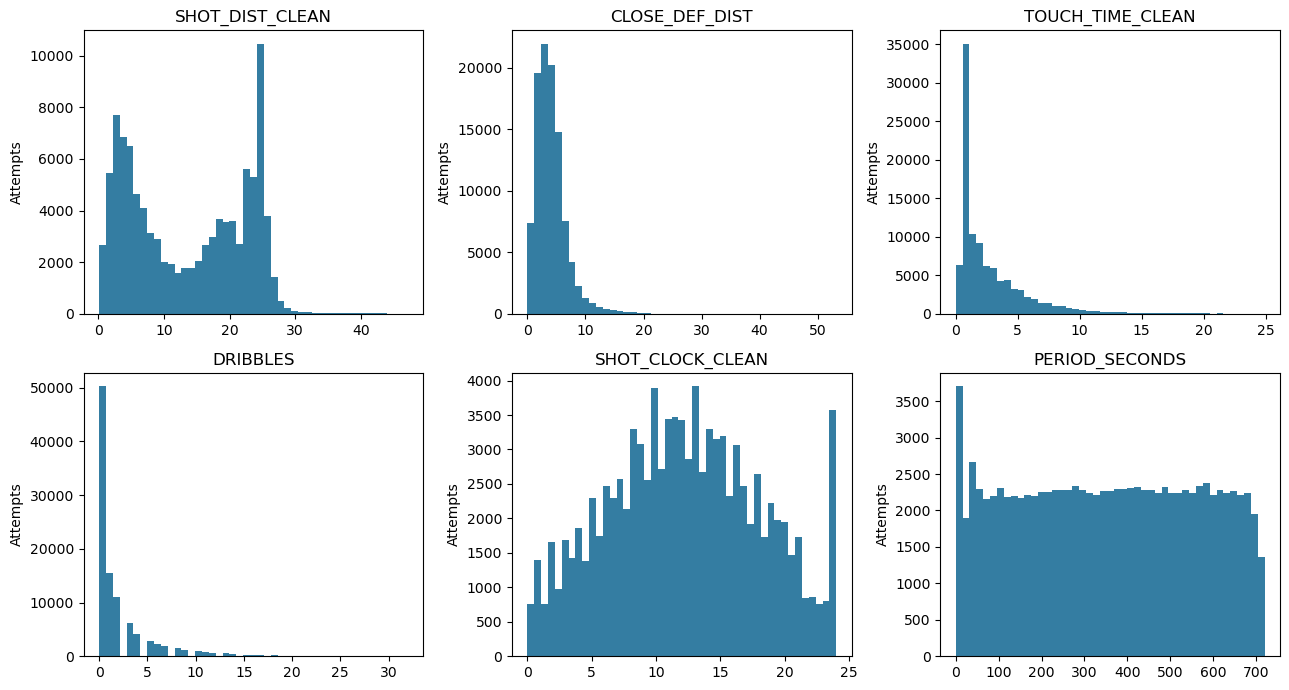

In [3]:
numeric_context = [
    "SHOT_DIST_CLEAN", "CLOSE_DEF_DIST", "TOUCH_TIME_CLEAN",
    "DRIBBLES", "SHOT_CLOCK_CLEAN", "PERIOD_SECONDS",
]
summary = shots[numeric_context].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T
summary["missing"] = shots[numeric_context].isna().sum()
display(summary.round(2))
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for feature, ax in zip(numeric_context, axes.flat):
    ax.hist(shots[feature].dropna(), bins=45, color="#347da2")
    ax.set(title=feature, ylabel="Attempts")
fig.tight_layout()
display(fig)
plt.close(fig)

,attempts
count,281.0
mean,363.0
std,187.6
min,41.0
25%,217.0
50%,334.0
75%,508.0
max,854.0


,,attempts,games,make_rate,three_share,mean_distance
player_id,player_name,,,,,
101145,mnta ellis,854,49,0.463,0.211,14.296
201935,james harden,852,47,0.455,0.379,14.897
201933,blake griffin,851,48,0.499,0.025,11.915
200746,lamarcus aldridge,845,42,0.465,0.059,13.687
203081,damian lillard,815,48,0.428,0.434,16.528
202681,kyrie irving,761,45,0.464,0.306,14.294
200768,kyle lowry,759,48,0.426,0.350,15.725
201939,stephen curry,747,45,0.486,0.458,17.241
202691,klay thompson,743,44,0.482,0.417,16.771


Shooters with fewer than 100 attempts: 14


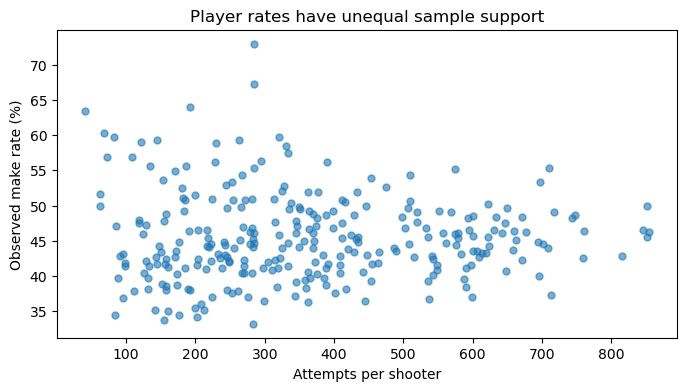

,,attempts,games,make_rate,three_share,mean_distance
player_id,player_name,,,,,
201599,deandre jordan,285,48,0.730,0.007,3.488
2199,tyson chandler,284,47,0.673,0.000,4.065
203497,rudy gobert,192,45,0.641,0.005,3.560
202962,greg smith,41,23,0.634,0.000,2.544
202366,jerome jordan,68,24,0.603,0.000,4.843
2365,chris andersen,82,26,0.598,0.024,5.740
203486,mason plumlee,320,46,0.597,0.009,4.181
202334,ed davis,263,46,0.593,0.000,4.454
203089,john henson,145,29,0.593,0.000,4.590


In [4]:
players = shots.groupby(["player_id", "player_name"]).agg(
    attempts=("FGM", "size"), games=("GAME_ID", "nunique"), make_rate=("FGM", "mean"),
    three_share=("PTS_TYPE", lambda x: x.eq(3).mean()),
    mean_distance=("SHOT_DIST_CLEAN", "mean"),
)
display(players["attempts"].describe().round(1).to_frame())
display(players.nlargest(12, "attempts").round(3))
print(f"Shooters with fewer than 100 attempts: {players['attempts'].lt(100).sum()}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(players["attempts"], players["make_rate"] * 100, alpha=.6, s=25)
ax.set(xlabel="Attempts per shooter", ylabel="Observed make rate (%)",
       title="Player rates have unequal sample support")
display(fig)
plt.close(fig)
display(players.nlargest(12, "make_rate").round(3))

A player leaderboard mixes shooting skill with shot selection. High-volume shooters contribute more to an overall rate, and low-volume rates can fluctuate substantially. The scatterplot shows where comparisons have little support. These player rates are descriptive summaries of the full exploration window and should never be copied into each row as a history feature.

## 3. Defender distance within comparable shots

The bands below use 0–<2, 2–<4, 4–<6, and 6+ ft. Distances to the basket use separate bands. First compare twos and threes, then look within basket-distance bands. This helps expose shot-mix effects that can reverse a pooled relationship.

attempts  make_pct  median_basket_distance
PTS_TYPE DEFENDER_BAND                                            
2        0–<2 ft           18370     46.15                     4.3
         2–<4 ft           32250     49.51                     6.5
         4–<6 ft           16891     49.14                    16.1
         6+ ft              7539     53.28                    18.3
3        0–<2 ft             475     24.00                    24.2
         2–<4 ft            4719     31.11                    24.5
         4–<6 ft           11135     34.93                    24.5
         6+ ft             10618     38.27                    24.4

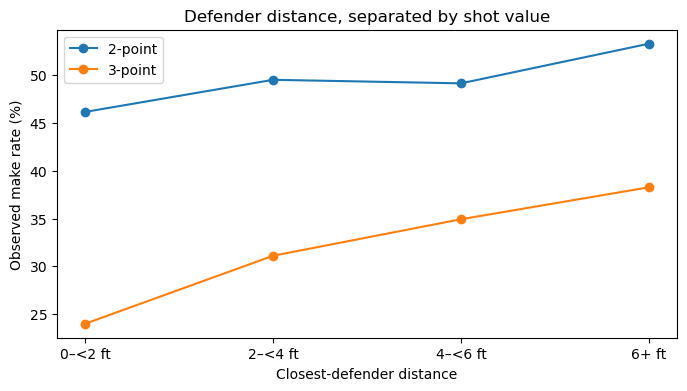

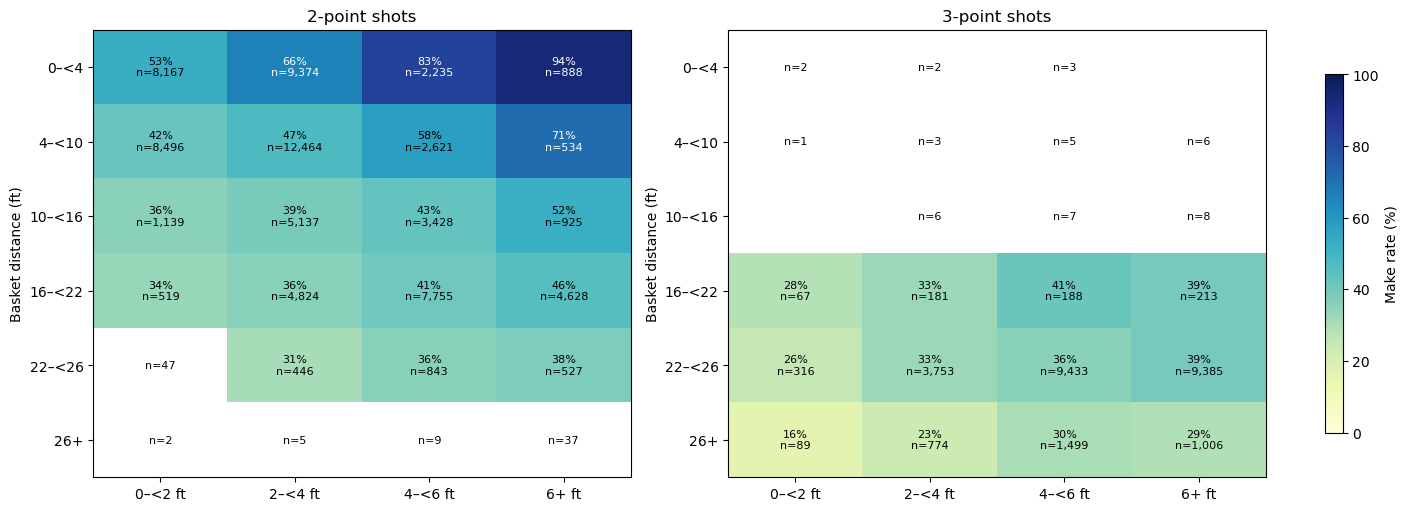

In [5]:
shots["DEFENDER_BAND"] = pd.cut(
    shots["CLOSE_DEF_DIST"], [0, 2, 4, 6, np.inf], right=False,
    labels=["0–<2 ft", "2–<4 ft", "4–<6 ft", "6+ ft"],
)
shots["BASKET_BAND"] = pd.cut(
    shots["SHOT_DIST_CLEAN"], [0, 4, 10, 16, 22, 26, np.inf], right=False,
    labels=["0–<4", "4–<10", "10–<16", "16–<22", "22–<26", "26+"],
)
contest = shots.groupby(["PTS_TYPE", "DEFENDER_BAND"], observed=True).agg(
    attempts=("FGM", "size"), make_pct=("FGM", lambda x: 100*x.mean()),
    median_basket_distance=("SHOT_DIST_CLEAN", "median"),
)
display(contest.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
for value in [2, 3]:
    group = contest.loc[value]
    ax.plot(group.index.astype(str), group["make_pct"], marker="o", label=f"{value}-point")
ax.set(xlabel="Closest-defender distance", ylabel="Observed make rate (%)",
       title="Defender distance, separated by shot value")
ax.legend()
display(fig)
plt.close(fig)

context_rates = shots.groupby(["PTS_TYPE", "BASKET_BAND", "DEFENDER_BAND"], observed=True)["FGM"].agg(
    attempts="size", make_rate="mean",
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for value, ax in zip([2, 3], axes):
    table = context_rates.loc[value]
    counts = table["attempts"].unstack("DEFENDER_BAND")
    rates = table["make_rate"].unstack("DEFENDER_BAND").mul(100)
    image = ax.imshow(rates.where(counts.ge(50)), vmin=0, vmax=100, cmap="YlGnBu", aspect="auto")
    ax.set(xticks=range(len(rates.columns)), xticklabels=rates.columns,
           yticks=range(len(rates.index)), yticklabels=rates.index,
           title=f"{value}-point shots", ylabel="Basket distance (ft)")
    for row in range(len(rates)):
        for col in range(len(rates.columns)):
            n = counts.iloc[row, col]
            if pd.notna(n):
                label = f"{rates.iloc[row, col]:.0f}%\nn={int(n):,}" if n >= 50 else f"n={int(n)}"
                ax.text(col, row, label, ha="center", va="center", fontsize=8,
                        color="white" if n >= 50 and rates.iloc[row, col] > 65 else "black")
fig.colorbar(image, ax=axes, label="Make rate (%)", shrink=.8)
display(fig)
plt.close(fig)

Each cell shows its sample count. Cells with fewer than 50 attempts have no rate color. Fifty is a readability threshold, not a guarantee of precision. A defender-distance association remains observational because shot type, shooter, defender, and defensive decisions also differ between cells.

**Observed pattern.** Three-point make rates rise from **24.0%** under 2 ft of defender distance to **38.3%** at 6+ ft. For two-pointers inside 4 ft of the basket, the corresponding rates are **53%** and **94%**. These are different shot mixtures, not estimates of how the same shot would change if a defender moved.

The three-point table also contains short recorded basket distances. Across this exploration window, **692 attempts labeled as threes have a recorded distance below 22 ft**. These label/distance combinations remain as recorded; the table alone cannot establish which field needs correction. Interpret the short-distance three-point cells with that limitation.

Inspect Damian Lillard's shots separately. A very small contested slice cannot establish his true ability in that context.

In [6]:
lillard = shots.loc[shots["player_id"].eq(203081) & shots["PTS_TYPE"].eq(2)]
lillard_rates = lillard.groupby("DEFENDER_BAND", observed=False)["FGM"].agg(attempts="size", makes="sum", make_rate="mean")
display(lillard_rates.round(3))
lillard = shots.loc[shots["player_id"].eq(203081) & shots["PTS_TYPE"].eq(3)]
lillard_rates = lillard.groupby("DEFENDER_BAND", observed=False)["FGM"].agg(attempts="size", makes="sum", make_rate="mean")
display(lillard_rates.round(3))

,attempts,makes,make_rate
DEFENDER_BAND,,,
0–<2 ft,102,40,0.392
2–<4 ft,215,109,0.507
4–<6 ft,115,61,0.530
6+ ft,29,14,0.483


,attempts,makes,make_rate
DEFENDER_BAND,,,
0–<2 ft,12,3,0.250
2–<4 ft,81,30,0.370
4–<6 ft,160,53,0.331
6+ ft,101,39,0.386


## 4. Numeric relationship matrices

Pearson correlation measures linear association. Spearman correlation measures association between ranks, which can help with skewed or nonlinear monotonic relationships. Neither captures every interaction. The make indicator is included to describe association with the outcome, and is excluded from transformations used later.

Correlations use the available pairs for each entry, so the observation counts can differ where touch time or shot clock is missing. Numeric category IDs are omitted because their magnitudes have no meaningful order. [Pandas correlation documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)

**Damian Lillard sample.** His threes include **12** attempts with a defender under 2 ft away, with **3 makes (25.0%)**. The other bands have **81, 160, and 101 attempts**, with make rates of **37.0%, 33.1%, and 38.6%**. The rates do not increase monotonically with openness, illustrating why the pooled trend cannot be assumed for every shooter. The tightly contested slice remains small.

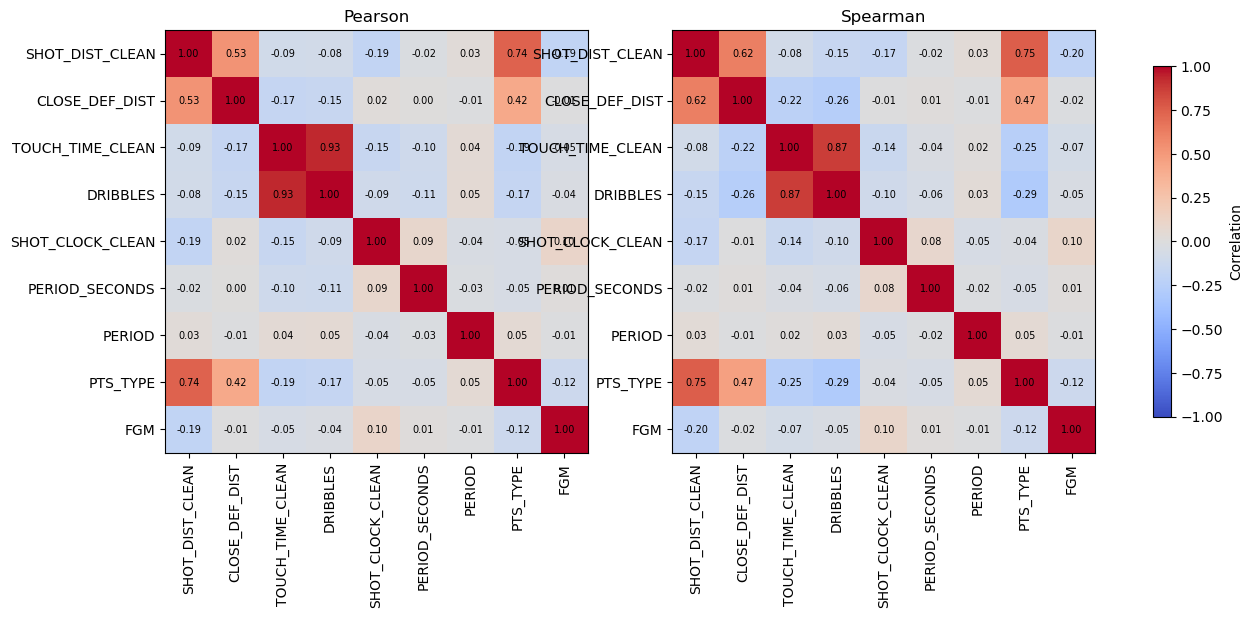

,Pearson with FGM,Spearman with FGM
SHOT_DIST_CLEAN,-0.193,-0.200
CLOSE_DEF_DIST,-0.006,-0.018
TOUCH_TIME_CLEAN,-0.050,-0.067
DRIBBLES,-0.036,-0.046
SHOT_CLOCK_CLEAN,0.105,0.098
PERIOD_SECONDS,0.011,0.011
PERIOD,-0.013,-0.012
PTS_TYPE,-0.120,-0.120


,SHOT_DIST_CLEAN,CLOSE_DEF_DIST,TOUCH_TIME_CLEAN,DRIBBLES,SHOT_CLOCK_CLEAN,PERIOD_SECONDS,PERIOD,PTS_TYPE,FGM
Pairwise available attempts,,,,,,,,,
SHOT_DIST_CLEAN,101997,101997,101739,101997,100758,101997,101997,101997,101997
CLOSE_DEF_DIST,101997,101997,101739,101997,100758,101997,101997,101997,101997
TOUCH_TIME_CLEAN,101739,101739,101739,101739,100506,101739,101739,101739,101739
DRIBBLES,101997,101997,101739,101997,100758,101997,101997,101997,101997
SHOT_CLOCK_CLEAN,100758,100758,100506,100758,100758,100758,100758,100758,100758
PERIOD_SECONDS,101997,101997,101739,101997,100758,101997,101997,101997,101997
PERIOD,101997,101997,101739,101997,100758,101997,101997,101997,101997
PTS_TYPE,101997,101997,101739,101997,100758,101997,101997,101997,101997
FGM,101997,101997,101739,101997,100758,101997,101997,101997,101997


In [7]:
relation_columns = numeric_context + ["PERIOD", "PTS_TYPE", "FGM"]
relations = shots[relation_columns]
pearson = relations.corr(method="pearson")
spearman = relations.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for matrix, name, ax in zip([pearson, spearman], ["Pearson", "Spearman"], axes):
    image = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set(xticks=range(len(matrix)), xticklabels=matrix.columns,
           yticks=range(len(matrix)), yticklabels=matrix.index, title=name)
    ax.tick_params(axis="x", labelrotation=90)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            ax.text(j, i, f"{matrix.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=axes, shrink=.65, label="Correlation")
display(fig)
plt.close(fig)
display(pd.DataFrame({
    "Pearson with FGM": pearson["FGM"].drop("FGM"),
    "Spearman with FGM": spearman["FGM"].drop("FGM"),
}).round(3))
valid = relations.notna().astype("int64")
display((valid.T @ valid).rename_axis("Pairwise available attempts"))

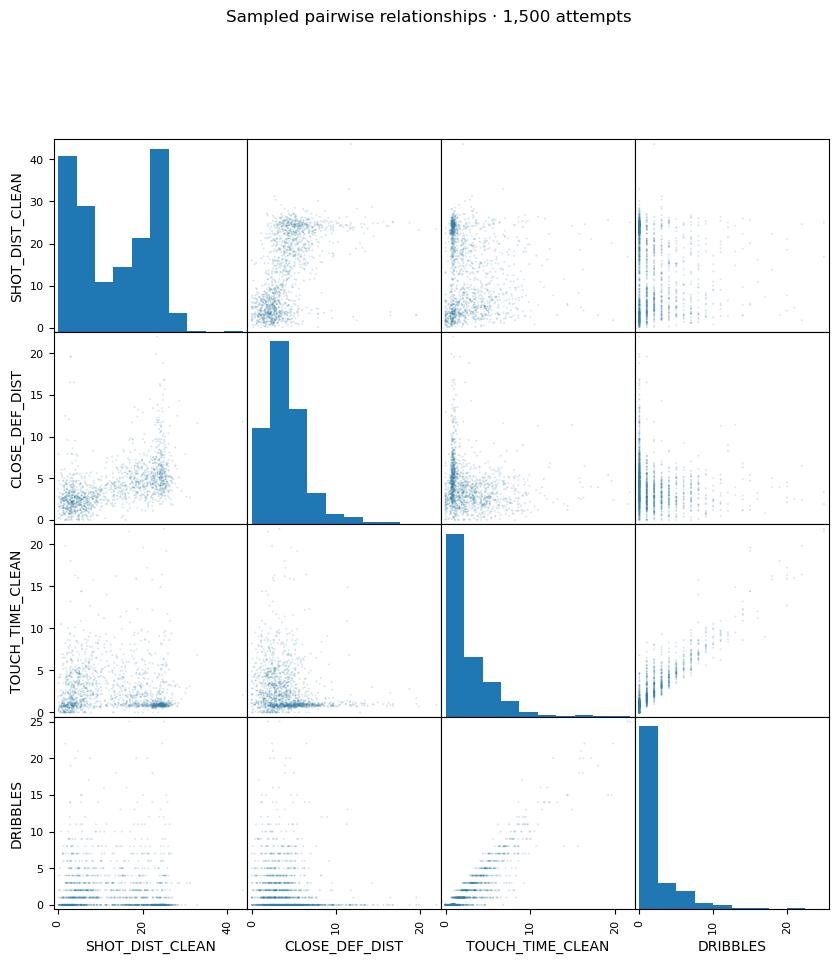

In [8]:
plot_columns = ["SHOT_DIST_CLEAN", "CLOSE_DEF_DIST", "TOUCH_TIME_CLEAN", "DRIBBLES"]
sample = shots.sample(n=min(1500, len(shots)), random_state=42)
axes = scatter_matrix(
    sample[plot_columns], figsize=(10, 10), diagonal="hist",
    alpha=.2, s=8, color="#347da2",
)
fig = axes[0, 0].figure
fig.suptitle("Sampled pairwise relationships · 1,500 attempts", y=1.01)
display(fig)
plt.close(fig)

A weak pooled correlation with make or miss is compatible with a useful contextual feature. For example, openness and basket distance can move together, while the make-rate relationship differs between twos and threes. The scatterplots reveal shape and tails, while the matrices summarize only one aspect of each relationship.

## 5. Dribbles, touch time, clocks, and location

These comparisons describe how attempts differ. They do not estimate the benefit of asking a player to take fewer dribbles or shoot earlier. For time, retain both period context and shot clock so that 5 s on the shot clock early in a quarter remains distinguishable from 5 s at period end.

**Matrix finding.** Overall Pearson correlation between defender distance and FGM is **−0.006**, despite the positive association within comparable shots above. Shot distance has a larger negative correlation (**−0.193**). This is a concrete reason to examine conditional relationships before deciding that a feature is uninformative.

In [9]:
shots["DRIBBLE_BAND"] = pd.cut(shots["DRIBBLES"], [-1, 0, 1, 3, np.inf], labels=["0", "1", "2–3", "4+"])
shots["TOUCH_BAND"] = pd.cut(shots["TOUCH_TIME_CLEAN"], [-.01, 2, 6, np.inf], right=False,
                              labels=["0–<2 s", "2–<6 s", "6+ s"])
shots["CLOCK_BAND"] = pd.cut(shots["SHOT_CLOCK_CLEAN"], [-.01, 4, 8, 16, np.inf], right=False,
                              labels=["0–<4 s", "4–<8 s", "8–<16 s", "16+ s"])
for feature in ["DRIBBLE_BAND", "TOUCH_BAND", "CLOCK_BAND", "LOCATION"]:
    print(feature)
    display(shots.groupby([feature, "PTS_TYPE"], observed=True).agg(
        attempts=("FGM", "size"), make_pct=("FGM", lambda x: 100*x.mean()),
        median_basket_distance=("SHOT_DIST_CLEAN", "median"),
    ).round(2))
print("Shot-clock provenance")
display(shots.groupby("CLOCK_SOURCE").agg(
    attempts=("FGM", "size"), median_period_seconds=("PERIOD_SECONDS", "median"),
    make_pct=("FGM", lambda x: 100*x.mean()),
).round(2))

DRIBBLE_BAND


attempts  make_pct  median_basket_distance
DRIBBLE_BAND PTS_TYPE                                            
0            2            29835     54.87                     5.4
             3            20438     36.74                    24.4
1            2            13290     47.63                     7.5
             3             2172     32.60                    24.6
2–3          2            15649     44.16                     7.9
             3             1646     27.83                    24.8
4+           2            16276     43.94                     8.7
             3             2691     31.96                    24.9

TOUCH_BAND


attempts  make_pct  median_basket_distance
TOUCH_BAND PTS_TYPE                                            
0–<2 s     2            34903     54.86                     5.8
           3            21335     36.38                    24.4
2–<6 s     2            29638     44.44                     8.0
           3             3918     30.78                    24.8
6+ s       2            10291     42.50                     9.0
           3             1654     33.37                    24.8

CLOCK_BAND


attempts  make_pct  median_basket_distance
CLOCK_BAND PTS_TYPE                                            
0–<4 s     2             6031     38.75                    10.8
           3             3160     25.73                    25.1
4–<8 s     2            11982     44.73                     8.9
           3             4262     35.36                    24.5
8–<16 s    2            35488     47.51                     8.9
           3            11824     37.03                    24.4
16+ s      2            20631     57.15                     4.3
           3             7380     36.87                    24.5

LOCATION


attempts  make_pct  median_basket_distance
LOCATION PTS_TYPE                                            
A        2            37485     48.68                     7.4
         3            13354     34.98                    24.5
H        2            37565     49.29                     7.3
         3            13593     35.78                    24.5

Shot-clock provenance


,attempts,median_period_seconds,make_pct
CLOCK_SOURCE,,,
Period proxy,2829,2.0,31.85
Possession estimate,558,352.5,46.77
Recorded,97371,362.0,45.81
Unresolved,1239,381.0,42.78


The provenance groups show different kinds of shots, so their outcome rates cannot establish whether reconstruction is accurate. Missing touch time and unresolved clocks are excluded from the corresponding bands above, and remain counted in the earlier coverage tables.

## 6. Time stability and usable player history

Track attempt volume, shot mix, and make rate by month. Changes could reflect game coverage, schedule, player composition, or genuine changes in play. A change in a pooled rate alone cannot distinguish those explanations.

,attempts,games,shooters,make_pct,three_share,mean_defender_distance,unresolved_clock_pct
GAME_DATE,,,,,,,
2014-10,3533,26,249,45.49,26.07,4.20,0.03
2014-11,30700,221,279,45.62,26.32,4.09,1.30
2014-12,34502,232,280,45.64,26.50,4.11,0.56
2015-01,33262,231,281,44.92,26.46,4.13,1.95


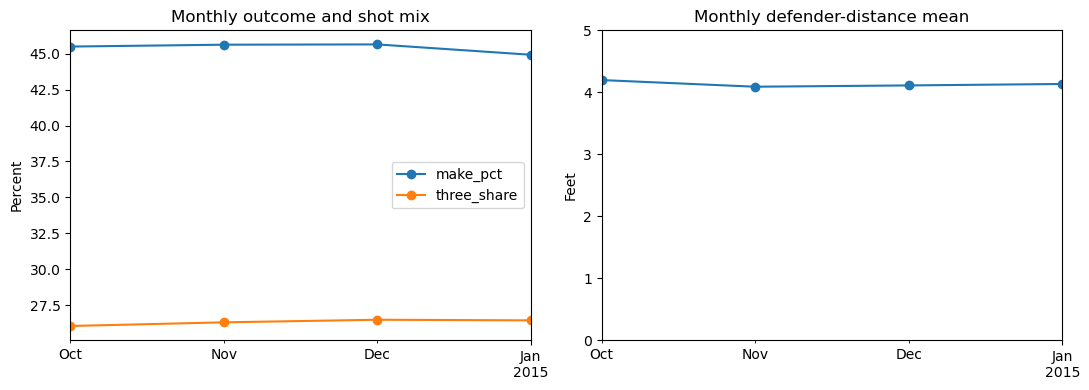

In [10]:
monthly = shots.groupby(shots["GAME_DATE"].dt.to_period("M")).agg(
    attempts=("FGM", "size"), games=("GAME_ID", "nunique"), shooters=("player_id", "nunique"),
    make_pct=("FGM", lambda x: 100*x.mean()), three_share=("PTS_TYPE", lambda x: 100*x.eq(3).mean()),
    mean_defender_distance=("CLOSE_DEF_DIST", "mean"),
    unresolved_clock_pct=("SHOT_CLOCK_CLEAN", lambda x: 100*x.isna().mean()),
)
display(monthly.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
monthly[["make_pct", "three_share"]].plot(marker="o", ax=axes[0], title="Monthly outcome and shot mix")
axes[0].set(ylabel="Percent", xlabel="")
monthly["mean_defender_distance"].plot(marker="o", ax=axes[1], title="Monthly defender-distance mean")
axes[1].set(ylabel="Feet", xlabel="", ylim=(0, 5))
fig.tight_layout()
display(fig)
plt.close(fig)

Player history should use attempts from earlier games. Because this file gives dates rather than game-start timestamps, the history below uses earlier dates and excludes every attempt on the current date. The table counts prior attempts without estimating a make probability. It shows how much support a future history feature would have.

**Time finding.** Monthly make rate stays near **45.5–45.6%** in October–December and is **44.9%** in January. Three-point share stays near **26%**. October covers only the opening days, so its lower attempt count does not imply a fall in data completeness. January also has a higher unresolved-clock share (**1.95%**) than December (**0.56%**).

In [11]:
daily = shots.groupby(["player_id", "GAME_DATE"], as_index=False).agg(attempts=("FGM", "size"))
daily = daily.sort_values(["player_id", "GAME_DATE"])
daily["PRIOR_ATTEMPTS"] = daily.groupby("player_id")["attempts"].cumsum() - daily["attempts"]
history = shots[["player_id", "GAME_DATE"]].merge(
    daily[["player_id", "GAME_DATE", "PRIOR_ATTEMPTS"]],
    how="left", on=["player_id", "GAME_DATE"], validate="many_to_one",
)
history["SUPPORT"] = pd.cut(history["PRIOR_ATTEMPTS"], [-1, 0, 19, 99, np.inf],
                           labels=["No prior attempts", "1–19", "20–99", "100+"])
display(history["SUPPORT"].value_counts(sort=False).to_frame("Current shots"))
assert history["PRIOR_ATTEMPTS"].notna().all()
print("Current-date outcomes are excluded from these history counts.")

,Current shots
SUPPORT,
No prior attempts,2345
1–19,4570
20–99,22293
100+,72789


Current-date outcomes are excluded from these history counts.


## 7. One-hot encoding

One-hot encoding creates a 0/1 column for each category. A shot can activate one shooter column, one closest-defender column, and the appropriate context columns. This avoids treating player 201939 as numerically greater than another player. The output is sparse because most category indicators are zero.

Fit the encoder on pre-January categories and transform January. Unseen categories become zeros within that feature's block under `handle_unknown="ignore"`; the printed check shows whether this occurs. Keeping all category columns makes the mapping easier to inspect here. An unregularized linear model with an intercept would need a reference category or another constraint. [Scikit-learn OneHotEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

In [12]:
early = shots.loc[shots["GAME_DATE"].lt("2015-01-01")].copy()
january = shots.loc[shots["GAME_DATE"].ge("2015-01-01")].copy()
assert set(early["GAME_ID"]).isdisjoint(january["GAME_ID"])
categories = ["player_id", "CLOSEST_DEFENDER_PLAYER_ID", "LOCATION", "PTS_TYPE", "PERIOD"]
early_categories = early[categories].astype("string").fillna("Unknown")
january_categories = january[categories].astype("string").fillna("Unknown")
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32)
encoded_early = encoder.fit_transform(early_categories)
encoded_january = encoder.transform(january_categories)
names = encoder.get_feature_names_out(categories)
display(pd.DataFrame({
    "Feature": categories,
    "Earlier categories": [len(values) for values in encoder.categories_],
    "January unseen rows": [
        (~january_categories[column].isin(values)).sum()
        for column, values in zip(categories, encoder.categories_)
    ],
}))
print(f"Earlier matrix: {encoded_early.shape}; January matrix: {encoded_january.shape}")
print(f"Earlier nonzero density: {encoded_early.nnz / np.prod(encoded_early.shape):.2%}")
preview = pd.DataFrame(encoded_early[:5].toarray(), columns=names)
display(early[categories].head().reset_index(drop=True))
display(preview.loc[:, preview.any(axis=0)])

,Feature,Earlier categories,January unseen rows
0,player_id,281,0
1,CLOSEST_DEFENDER_PLAYER_ID,445,402
2,LOCATION,2,0
3,PTS_TYPE,2,0
4,PERIOD,7,0


Earlier matrix: (68735, 737); January matrix: (33262, 737)
Earlier nonzero density: 0.68%


,player_id,CLOSEST_DEFENDER_PLAYER_ID,LOCATION,PTS_TYPE,PERIOD
0,203148,201147,A,3,2
1,203148,1891,A,2,4
2,203148,1891,A,2,4
3,203148,2746,A,2,4
4,203148,1891,A,3,4


,player_id_203148,CLOSEST_DEFENDER_PLAYER_ID_1891,CLOSEST_DEFENDER_PLAYER_ID_201147,CLOSEST_DEFENDER_PLAYER_ID_2746,LOCATION_A,PTS_TYPE_2,PTS_TYPE_3,PERIOD_2,PERIOD_4
0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
1,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
3,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0
4,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


This creates an inspected category representation. It does not choose the final model. Shooter identity has enough categories that rare players may need regularization or shared information from earlier shooting history. Closest-defender identity can similarly reflect both defensive skill and matchup selection.

## 8. Principal component analysis (PCA)

PCA finds directions that explain variance in numeric inputs. Variance refers to how the inputs vary, so the first component need not be the best direction for predicting makes.

Use six context features and exclude category IDs and outcomes. Fill missing values with pre-January medians, standardize using pre-January means and standard deviations, then fit PCA on that same earlier sample. Standardization prevents units such as period seconds from dominating feet merely through their scale. January receives the existing transformations. Median filling supplies a value for PCA's required complete matrix and is specific to this exploration.

The cumulative variance plot shows how much numeric variation survives as components are retained. The weight table shows each original standardized feature's contribution. Component signs can flip without changing the result. The score plots are limited projections, and retained extremes can influence the components. [Scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)

The fitted categorical representation has **737 columns** for **68,735 earlier attempts**, with the same output width for **33,262 January attempts**. This illustrates how player and defender identities expand the input even though the raw table has few columns.

,explained_share,cumulative_share
PC1,0.348,0.348
PC2,0.249,0.597
PC3,0.167,0.764
PC4,0.153,0.917
PC5,0.072,0.989
PC6,0.011,1.000


,PC1,PC2,PC3,PC4,PC5,PC6
SHOT_DIST_CLEAN,-0.238,0.665,0.103,-0.032,0.700,0.009
CLOSE_DEF_DIST,-0.313,0.559,0.294,0.236,-0.670,0.006
TOUCH_TIME_CLEAN,0.641,0.211,0.203,0.019,-0.021,0.709
DRIBBLES,0.635,0.207,0.231,0.076,-0.002,-0.703
SHOT_CLOCK_CLEAN,-0.118,-0.355,0.547,0.705,0.248,0.044
PERIOD_SECONDS,-0.134,-0.181,0.713,-0.663,-0.009,-0.011


,pre-January median
SHOT_DIST_CLEAN,13.7
CLOSE_DEF_DIST,3.7
TOUCH_TIME_CLEAN,1.6
DRIBBLES,1.0
SHOT_CLOCK_CLEAN,12.0
PERIOD_SECONDS,351.0


Components for at least 90% variance: 4


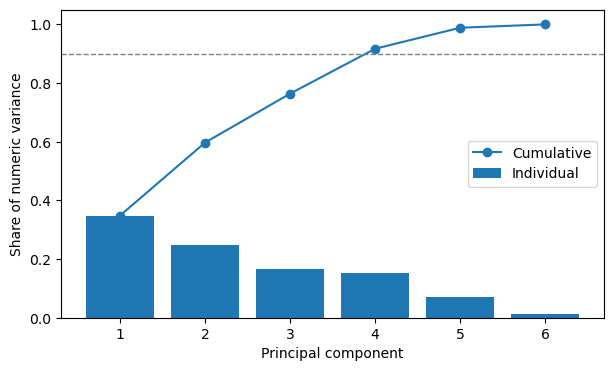

In [13]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
early_imputed = imputer.fit_transform(early[numeric_context])
early_scaled = scaler.fit_transform(early_imputed)
january_scaled = scaler.transform(imputer.transform(january[numeric_context]))
pca = PCA(svd_solver="full")
early_scores = pca.fit_transform(early_scaled)
january_scores = pca.transform(january_scaled)
variance = pd.DataFrame({
    "explained_share": pca.explained_variance_ratio_,
    "cumulative_share": pca.explained_variance_ratio_.cumsum(),
}, index=[f"PC{i+1}" for i in range(len(numeric_context))])
weights = pd.DataFrame(pca.components_.T, index=numeric_context, columns=variance.index)
display(variance.round(3))
display(weights.round(3))
display(pd.DataFrame({"pre-January median": imputer.statistics_}, index=numeric_context).round(2))
print(f"Components for at least 90% variance: {np.searchsorted(variance['cumulative_share'], .9) + 1}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, 7), variance["explained_share"], label="Individual")
ax.plot(range(1, 7), variance["cumulative_share"], marker="o", label="Cumulative")
ax.axhline(.9, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Principal component", ylabel="Share of numeric variance", ylim=(0, 1.05))
ax.legend()
display(fig)
plt.close(fig)

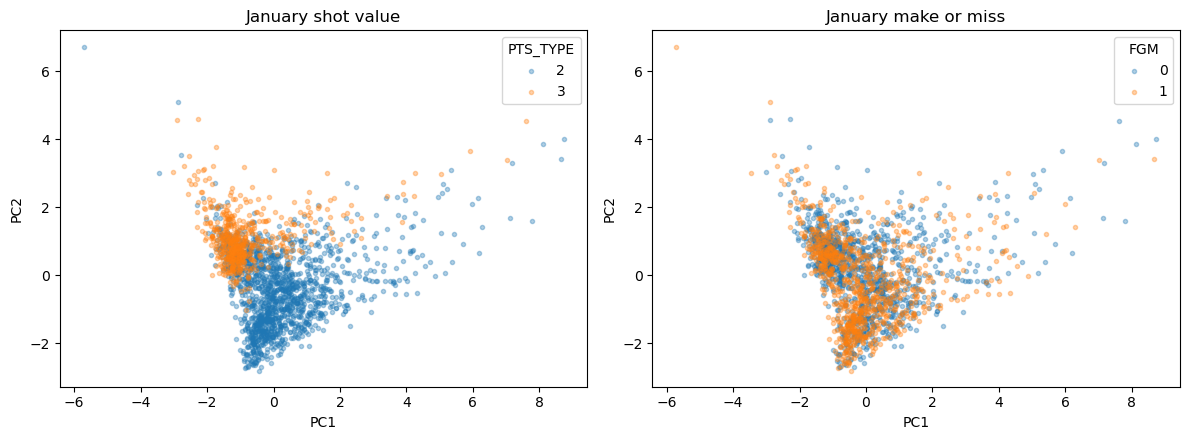

,largest absolute weight,signed weight
PC1,TOUCH_TIME_CLEAN,0.641
PC2,SHOT_DIST_CLEAN,0.665
PC3,PERIOD_SECONDS,0.713
PC4,SHOT_CLOCK_CLEAN,0.705
PC5,SHOT_DIST_CLEAN,0.700
PC6,TOUCH_TIME_CLEAN,0.709


Largest earlier-sample distances from the origin in the first two PCs


,SHOT_DIST_CLEAN,CLOSE_DEF_DIST,TOUCH_TIME_CLEAN,DRIBBLES,SHOT_CLOCK_CLEAN,PERIOD_SECONDS
89106,7.3,52.6,2.0,2,22.0,399
121565,18.2,5.2,21.2,32,3.0,8
34187,25.8,4.2,24.1,28,2.0,2
77107,8.0,1.3,22.1,31,1.9,20
76842,26.6,3.1,22.9,30,1.1,6


PC1 and PC2 preserve 59.7% of numeric variance.


In [14]:
rng = np.random.default_rng(42)
indices = rng.choice(len(january), size=min(2000, len(january)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column, title in zip(axes, ["PTS_TYPE", "FGM"], ["January shot value", "January make or miss"]):
    colors = january.iloc[indices][column].to_numpy()
    for value in sorted(np.unique(colors)):
        mask = colors == value
        ax.scatter(january_scores[indices[mask], 0], january_scores[indices[mask], 1],
                   s=9, alpha=.35, label=str(value))
    ax.set(xlabel="PC1", ylabel="PC2", title=title)
    ax.legend(title=column)
fig.tight_layout()
display(fig)
plt.close(fig)

dominant = weights.abs().idxmax()
display(pd.DataFrame({"largest absolute weight": dominant, "signed weight": [
    weights.loc[dominant[component], component] for component in weights.columns
]}).round(3))
extreme_scores = np.linalg.norm(early_scores[:, :2], axis=1)
print("Largest earlier-sample distances from the origin in the first two PCs")
display(early.iloc[np.argsort(extreme_scores)[-5:]][numeric_context])
print(f"PC1 and PC2 preserve {variance['explained_share'].iloc[:2].sum():.1%} of numeric variance.")

PCA mixes original features into components, which makes a statement such as “increase defender distance” harder to interpret. The original numeric features are few enough to inspect individually. These results can help identify redundancy, but any later choice to use PCA needs validation against a model using the original inputs.

## 9. What this EDA contributes to modeling

- Keep shot value and distance in context when assessing defender distance. The cell counts show which combinations have enough support to explore.
- Use shooter identity and earlier shooting history with attention to player sample size. A full-window make rate is a descriptive result and would leak later outcomes into earlier rows if used directly.
- Preserve the agreed anomaly treatments and clock provenance. The model input clock mixes recorded values, period proxies, and reconstructed estimates.
- Keep game boundaries and chronology intact when evaluating. Multiple attempts by one player or in one game share context.
- Treat correlations and PCA as descriptions of this sample. Validation must decide whether an encoding, transformation, or feature improves probability estimates.

The archive supports analysis of observed shots. It does not contain every possession, exact court location, or a randomized assignment of defensive pressure. Those limits shape which basketball questions these plots can answer.

**PCA finding.** PC1 and PC2 preserve **59.7%** of numeric variance. Four components reach **91.7%**. PC1 has its largest weights on touch time and dribbles, while PC2 emphasizes basket and defender distance. The near-redundancy between touch time and dribbles leaves only **1.1%** for PC6. These variance percentages do not measure accuracy at predicting makes.